# Garbage Classification using CNN
## Jupyter Notebook: Model Development, Evaluation, and Export

**Project purpose:** พัฒนาโมเดล Convolutional Neural Network (CNN) เพื่อจำแนกรูปภาพขยะออกเป็น 12 ประเภท และบันทึกโมเดลเพื่อนำไปใช้งานในเว็บแอป

**Dataset source:** [Garbage Classification — Kaggle](https://www.kaggle.com/datasets/mostafaabla/garbage-classification/data)  
**วันที่ค้นหาแหล่งข้อมูล:** 30 September 2026  
**Image size:** 64 × 64 pixels  
**Model type:** Supervised learning — CNN

### Classes
`battery`, `biological`, `brown-glass`, `cardboard`, `clothes`, `green-glass`, `metal`, `paper`, `plastic`, `shoes`, `trash`, `white-glass`

### Workflow
1. Import libraries and set reproducibility.
2. Download and locate the dataset.
3. Explore the dataset and visualize class distribution.
4. Preprocess images and split into train, validation, and test sets.
5. Build and train a CNN using only training data; use validation data for monitoring.
6. Evaluate the final model on the test set.
7. Inspect prediction examples and classification errors.
8. Save the model and metadata for deployment.

> **Data leakage prevention:** The test set is kept separate and is not used for training, model selection, or hyperparameter tuning. Validation data is used to monitor training and select the best epoch.

## 1. Import Libraries and Set Configuration
ติดตั้งไลบรารีที่จำเป็นใน environment หากยังไม่ได้ติดตั้ง จากนั้นกำหนดค่าพื้นฐานและ random seed เพื่อให้ผลการแบ่งข้อมูลทำซ้ำได้

In [1]:
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from pathlib import Path
from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

SEED = 42
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 20

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

EXPECTED_CLASSES = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Expected classes:", len(EXPECTED_CLASSES))

c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow version: 2.21.0
Image size: 64 x 64
Expected classes: 12


## 2. Download and Locate the Dataset
ดาวน์โหลด Dataset จาก Kaggle ผ่าน `kagglehub` และค้นหาโฟลเดอร์ที่มีคลาสทั้ง 12 ประเภทโดยอัตโนมัติ หากดาวน์โหลดไม่สำเร็จ ให้ตรวจสอบการเชื่อมต่ออินเทอร์เน็ตและสิทธิ์การเข้าถึง Dataset

In [2]:
DATASET_ROOT = kagglehub.dataset_download(
    "mostafaabla/garbage-classification"
)
print("Downloaded dataset to:", DATASET_ROOT)

expected_set = set(EXPECTED_CLASSES)

def find_dataset_path(root):
    root = Path(root)
    for current, dirs, files in os.walk(root):
        folder_names = set(dirs)
        if expected_set.issubset(folder_names):
            return Path(current)
    raise FileNotFoundError(
        "Could not find a directory containing all 12 expected class folders. "
        f"Downloaded root: {root}"
    )

DATASET_PATH = find_dataset_path(DATASET_ROOT)
classes = EXPECTED_CLASSES.copy()
class_to_idx = {name: i for i, name in enumerate(classes)}

print("Dataset path:", DATASET_PATH)
print("Class mapping:")
for name, index in class_to_idx.items():
    print(f"{index:2d}: {name}")

Downloaded dataset to: C:\Users\User\.cache\kagglehub\datasets\mostafaabla\garbage-classification\versions\1
Dataset path: C:\Users\User\.cache\kagglehub\datasets\mostafaabla\garbage-classification\versions\1\garbage_classification
Class mapping:
 0: battery
 1: biological
 2: brown-glass
 3: cardboard
 4: clothes
 5: green-glass
 6: metal
 7: paper
 8: plastic
 9: shoes
10: trash
11: white-glass


## 3. Load Images and Explore the Dataset
อ่านภาพจากแต่ละโฟลเดอร์ แปลงเป็น RGB และปรับขนาดเป็น 64 × 64 pixels ภาพที่อ่านไม่ได้จะถูกข้าม พร้อมรายงานจำนวนภาพที่โหลดได้จริง

In [3]:
images = []
labels = []
skipped_files = []

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_name in classes:
    class_dir = DATASET_PATH / class_name
    class_files = sorted(
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in valid_extensions
    )

    for file_path in class_files:
        try:
            with Image.open(file_path) as img:
                img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
                images.append(np.asarray(img, dtype=np.uint8))
                labels.append(class_to_idx[class_name])
        except (UnidentifiedImageError, OSError, ValueError) as exc:
            skipped_files.append(str(file_path))

X = np.asarray(images, dtype=np.uint8)
y = np.asarray(labels, dtype=np.int32)

if len(X) == 0:
    raise ValueError("No images were loaded. Check DATASET_PATH and class folders.")

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Images skipped:", len(skipped_files))
print("Total loaded images:", len(X))
print("Image dtype before normalization:", X.dtype)

Images shape: (15515, 64, 64, 3)
Labels shape: (15515,)
Images skipped: 0
Total loaded images: 15515
Image dtype before normalization: uint8


Number of images in each class:
battery: 945
biological: 985
brown-glass: 607
cardboard: 891
clothes: 5325
green-glass: 629
metal: 769
paper: 1050
plastic: 865
shoes: 1977
trash: 697
white-glass: 775


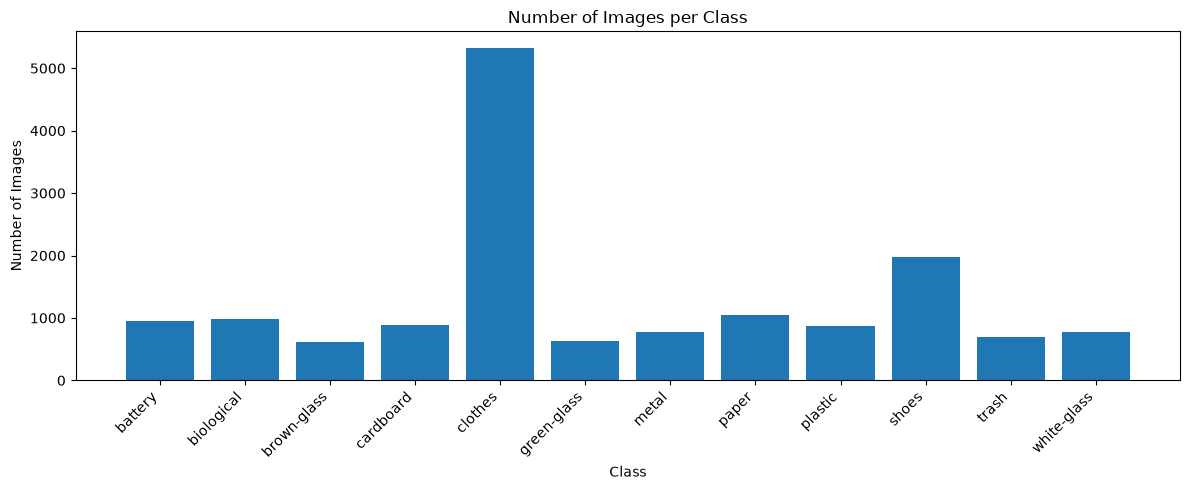

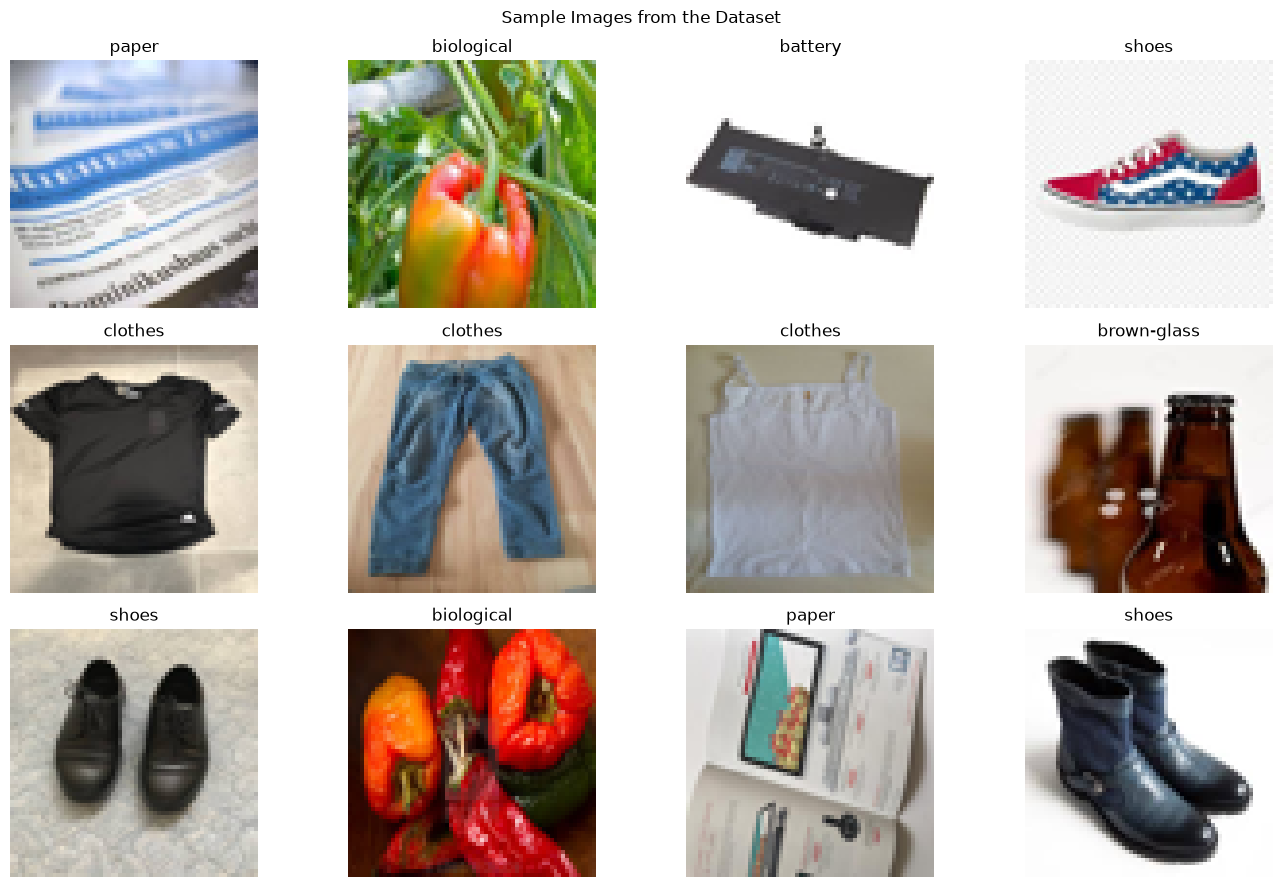

In [4]:
class_counts = np.bincount(y, minlength=len(classes))

print("Number of images in each class:")
for class_name, count in zip(classes, class_counts):
    print(f"{class_name}: {count}")

plt.figure(figsize=(12, 5))
plt.bar(classes, class_counts)
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

sample_count = min(12, len(X))
sample_indices = random.sample(range(len(X)), sample_count)

plt.figure(figsize=(14, 9))
for plot_idx, data_idx in enumerate(sample_indices, start=1):
    plt.subplot(3, 4, plot_idx)
    plt.imshow(X[data_idx])
    plt.title(classes[y[data_idx]])
    plt.axis("off")
plt.suptitle("Sample Images from the Dataset")
plt.tight_layout()
plt.show()

## 4. Preprocessing and Train / Validation / Test Split

- แปลงค่า Pixel จากช่วง 0–255 เป็นช่วง 0–1
- แบ่งข้อมูลเป็น **Training 64% / Validation 16% / Test 20%** ของข้อมูลทั้งหมด (โดยประมาณ)
- ใช้ stratified split เพื่อรักษาสัดส่วนของแต่ละคลาสให้ใกล้เคียงกัน
- Validation set ใช้ติดตามการฝึกและเลือก epoch ที่ดีที่สุด
- Test set เก็บไว้ประเมินผลขั้นสุดท้ายเท่านั้น

การแบ่งสองขั้นตอนด้านล่างทำให้ Test Set ถูกกันออกก่อน แล้วจึงแบ่งข้อมูลที่เหลือเป็น Training และ Validation

In [5]:
# Split off the test set first. Do not use it for training or model selection.
X_trainval_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Validation is 20% of the remaining 80% = 16% of the full dataset.
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_trainval_raw,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

# Normalize pixels consistently across all splits.
X_train = X_train_raw.astype("float32") / 255.0
X_val = X_val_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

print(f"Training:   {len(X_train):,} images ({len(X_train)/len(X):.1%})")
print(f"Validation: {len(X_val):,} images ({len(X_val)/len(X):.1%})")
print(f"Test:       {len(X_test):,} images ({len(X_test)/len(X):.1%})")
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
print("Pixel range:", float(X_train.min()), "to", float(X_train.max()))

Training:   9,929 images (64.0%)
Validation: 2,483 images (16.0%)
Test:       3,103 images (20.0%)
Train shape: (9929, 64, 64, 3)
Validation shape: (2483, 64, 64, 3)
Test shape: (3103, 64, 64, 3)
Pixel range: 0.0 to 1.0


## 5. Build the CNN Model

เลือกใช้ CNN เพราะ Convolutional layers สามารถเรียนรู้คุณลักษณะเชิงพื้นที่จากภาพ เช่น ขอบ รูปร่าง และพื้นผิวได้ โดยไม่ต้องแปลงภาพเป็นเวกเตอร์ก่อนเหมือนวิธีดั้งเดิม

- `Conv2D`: เรียนรู้คุณลักษณะของภาพ
- `MaxPooling2D`: ลดขนาด feature maps
- `Flatten` และ `Dense`: ใช้คุณลักษณะที่เรียนรู้มาเพื่อจำแนกคลาส
- `Dropout`: ช่วยลดความเสี่ยงของ overfitting
- `softmax`: ให้ความน่าจะเป็นของแต่ละคลาส
- `sparse_categorical_crossentropy`: เหมาะกับ label ที่เป็นเลขจำนวนเต็ม

In [6]:
model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,748 (2.61 MB)

 Trainable params: 684,748 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the CNN
ฝึกด้วย Training Set และใช้ Validation Set เพื่อติดตามผลระหว่างการฝึก `EarlyStopping` หยุดการฝึกเมื่อ validation loss ไม่ดีขึ้น และคืนค่าน้ำหนักจาก epoch ที่ดีที่สุด ไม่ได้นำ Test Set มาใช้ในขั้นตอนนี้

In [7]:
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = MODEL_DIR / "trash_class_cnn_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.4536 - loss: 1.6877
Epoch 1: val_loss improved from None to 1.29193, saving model to model\trash_class_cnn_best.keras

Epoch 1: finished saving model to model\trash_class_cnn_best.keras
311/311 ━━━━━━━━━━━━━━━━━━━━ 30s 79ms/step - accuracy: 0.4536 - loss: 1.6877 - val_accuracy: 0.5884 - val_loss: 1.2919
Epoch 2/20
310/311 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5751 - loss: 1.2926
Epoch 2: val_loss improved from 1.29193 to 1.15671, saving model to model\trash_class_cnn_best.keras

Epoch 2: finished saving model to model\trash_class_cnn_best.keras
311/311 ━━━━━━━━━━━━━━━━━━━━ 21s 66ms/step - accuracy: 0.5750 - loss: 1.2927 - val_accuracy: 0.6089 - val_loss: 1.1567
Epoch 3/20
310/311 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.6313 - loss: 1.1267
Epoch 3: val_loss improved from 1.15671 to 0.99846, saving model to model\trash_class_cnn_best.keras

Epoch 3: finished saving model to model\trash_class_cnn_best.ker

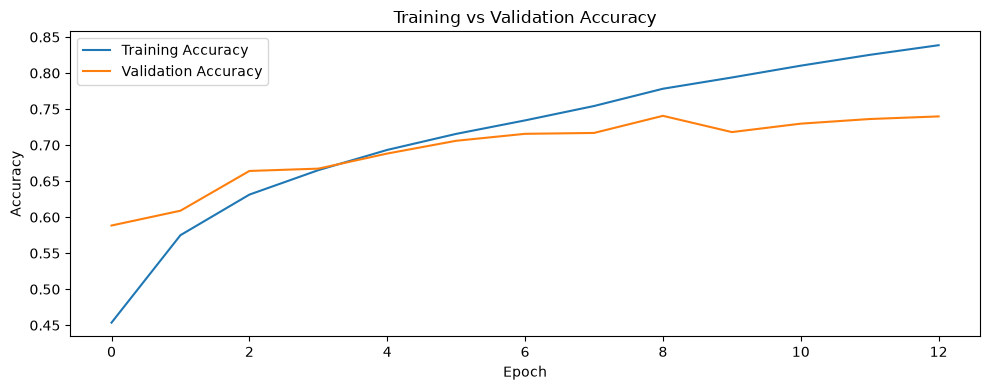

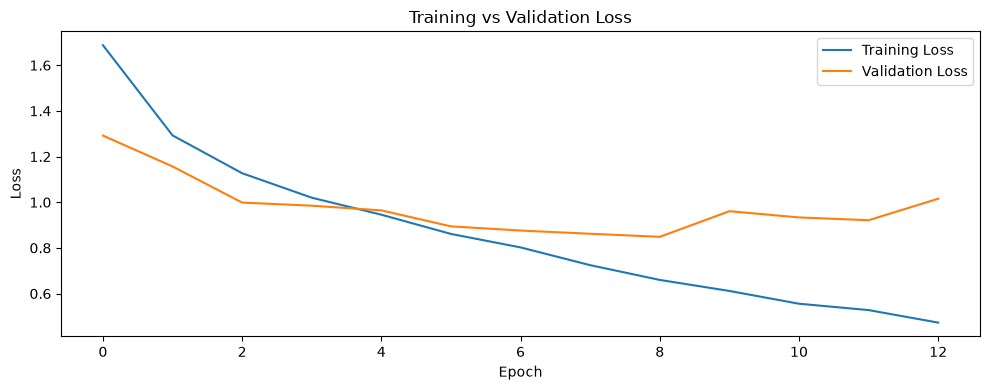

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Final Evaluation on the Test Set

ส่วนนี้ประเมินโมเดลที่ฝึกเสร็จแล้วบน Test Set ซึ่งไม่ได้ใช้ฝึกหรือเลือก epoch

- **Accuracy:** สัดส่วนของภาพที่จำแนกถูกต้องทั้งหมด
- **Precision:** ในภาพที่โมเดลทำนายว่าเป็นคลาสหนึ่ง มีสัดส่วนที่ถูกต้องเท่าใด
- **Recall:** จากภาพที่เป็นคลาสนั้นจริง โมเดลค้นพบได้เท่าใด
- **F1-score:** ค่าเฉลี่ยเชิงฮาร์มอนิกของ Precision และ Recall
- **Macro average:** เฉลี่ยแต่ละคลาสโดยให้น้ำหนักเท่ากัน
- **Weighted average:** เฉลี่ยโดยคำนึงถึงจำนวนตัวอย่างในแต่ละคลาส

In [9]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
test_probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
y_pred = np.argmax(test_probabilities, axis=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print()
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0,
    digits=4
))

97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7441 - loss: 0.8740
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
Test Loss: 0.8740
Test Accuracy: 0.7441 (74.41%)

              precision    recall  f1-score   support

     battery     0.6635    0.7407    0.7000       189
  biological     0.8198    0.4619    0.5909       197
 brown-glass     0.6118    0.7623    0.6788       122
   cardboard     0.7386    0.7303    0.7345       178
     clothes     0.8821    0.9343    0.9074      1065
 green-glass     0.8699    0.8492    0.8594       126
       metal     0.5038    0.4286    0.4632       154
       paper     0.6916    0.7048    0.6981       210
     plastic     0.5371    0.5434    0.5402       173
       shoes     0.6622    0.7494    0.7031       395
       trash     0.5951    0.6978    0.6424       139
 white-glass     0.7222    0.3355    0.4581       155

    accuracy                         0.7441      3103
   macro avg     0.6915    0.6615    0.6647      3103
weighted avg     0.7457 

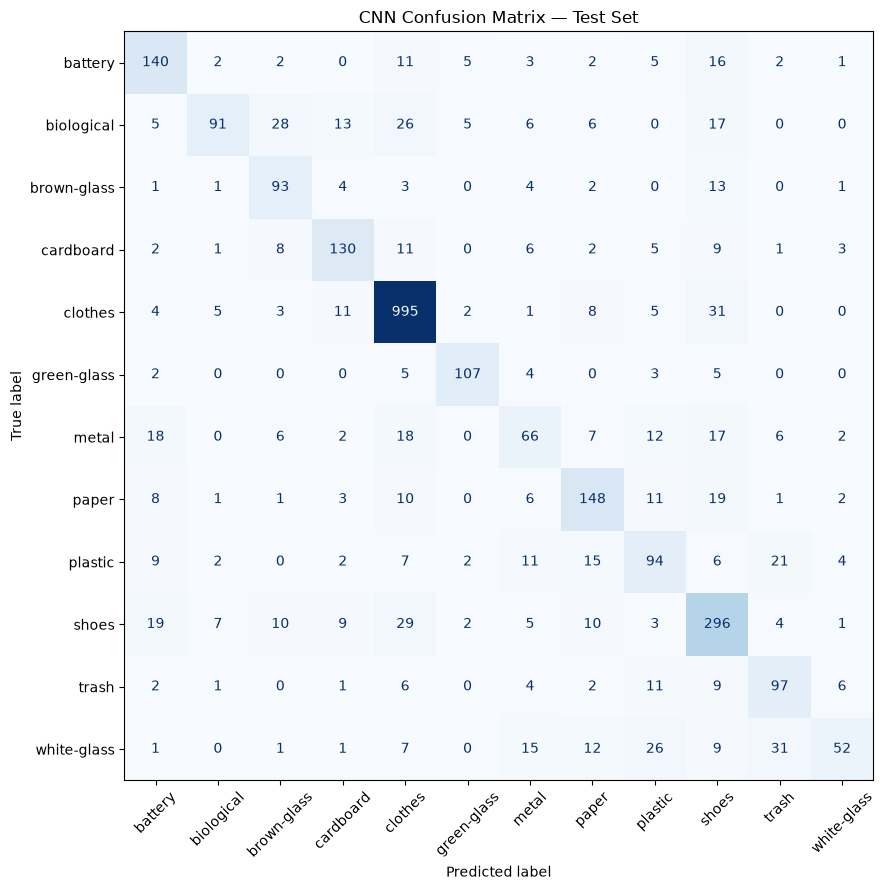

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(classes))
)

fig, ax = plt.subplots(figsize=(11, 9))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("CNN Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

## 8. Prediction Examples and Error Analysis
แสดงตัวอย่างภาพจาก Test Set พร้อมคลาสจริง คลาสที่ทำนาย และ confidence ของคลาสที่ทำนายได้ จากนั้นแสดงตัวอย่างที่ทำนายผิดเพื่อช่วยวิเคราะห์ข้อจำกัดของโมเดล

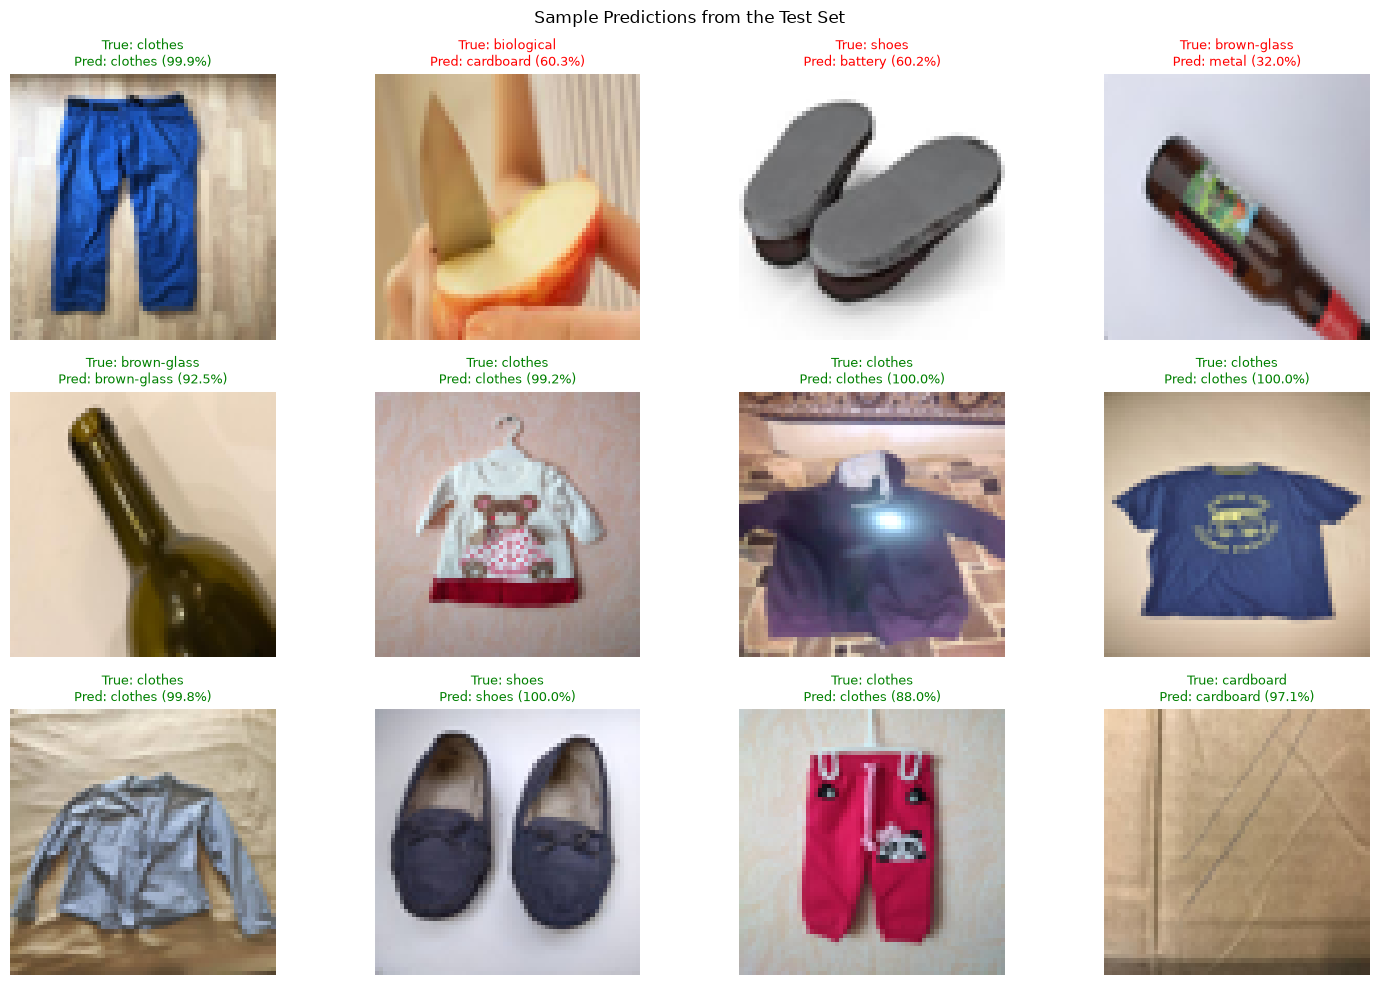

In [11]:
# Display a small sample of test predictions.
num_samples = min(12, len(X_test))
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_test), size=num_samples, replace=False)

plt.figure(figsize=(15, 10))
for plot_idx, idx in enumerate(sample_indices, start=1):
    pred_idx = int(y_pred[idx])
    true_idx = int(y_test[idx])
    confidence = float(test_probabilities[idx, pred_idx]) * 100

    plt.subplot(3, 4, plot_idx)
    plt.imshow(X_test[idx])
    title_color = "green" if pred_idx == true_idx else "red"
    plt.title(
        f"True: {classes[true_idx]}\nPred: {classes[pred_idx]} ({confidence:.1f}%)",
        color=title_color,
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("Sample Predictions from the Test Set")
plt.tight_layout()
plt.show()

Misclassified test images: 794 / 3103


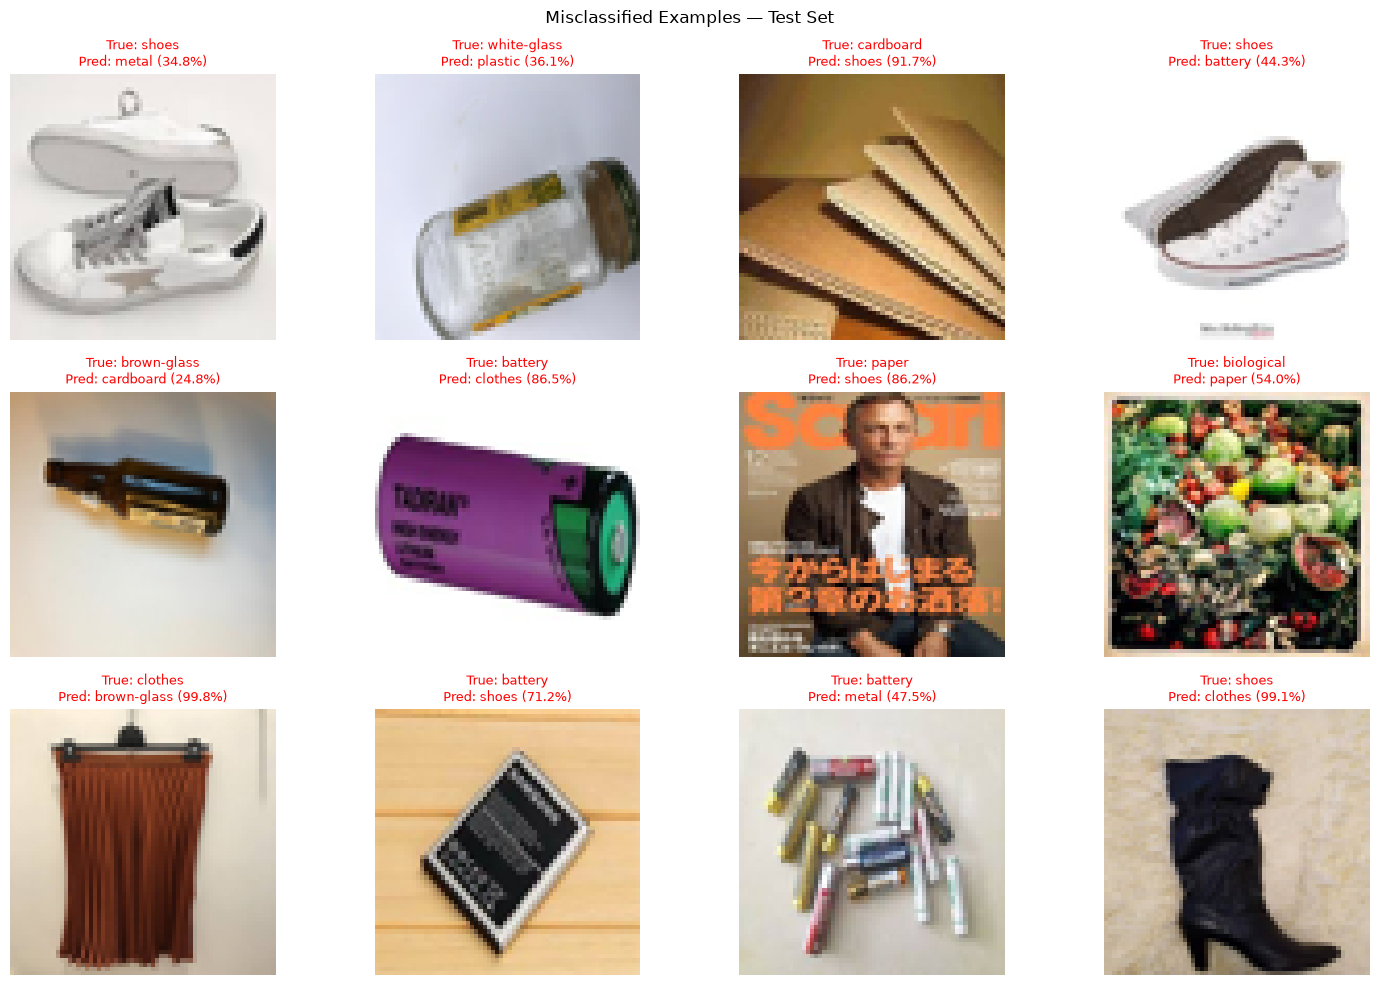


Error analysis prompts:
- Are the two classes visually similar (e.g., glass colors)?
- Is the object small, partly hidden, blurry, or poorly lit?
- Does the image contain multiple objects or a complex background?
- Check the images before drawing conclusions; do not assume a cause without inspection.


In [12]:
wrong_indices = np.where(y_pred != y_test)[0]
print(f"Misclassified test images: {len(wrong_indices)} / {len(y_test)}")

if len(wrong_indices) == 0:
    print("No misclassified examples in this test set.")
else:
    num_errors = min(12, len(wrong_indices))
    error_indices = wrong_indices[:num_errors]

    plt.figure(figsize=(15, 10))
    for plot_idx, idx in enumerate(error_indices, start=1):
        pred_idx = int(y_pred[idx])
        true_idx = int(y_test[idx])
        confidence = float(test_probabilities[idx, pred_idx]) * 100

        plt.subplot(3, 4, plot_idx)
        plt.imshow(X_test[idx])
        plt.title(
            f"True: {classes[true_idx]}\nPred: {classes[pred_idx]} ({confidence:.1f}%)",
            color="red",
            fontsize=9
        )
        plt.axis("off")

    plt.suptitle("Misclassified Examples — Test Set")
    plt.tight_layout()
    plt.show()

    print("\nError analysis prompts:")
    print("- Are the two classes visually similar (e.g., glass colors)?")
    print("- Is the object small, partly hidden, blurry, or poorly lit?")
    print("- Does the image contain multiple objects or a complex background?")
    print("- Check the images before drawing conclusions; do not assume a cause without inspection.")

## 9. Save the Model and Metadata for the Web App

บันทึกโมเดลที่ผ่านการฝึกเป็นไฟล์ `.keras` และบันทึก Metadata เป็น JSON เพื่อให้เว็บแอปอ่านลำดับคลาสและขนาดภาพได้ตรงกับตอนฝึก

`test_accuracy` เป็นค่าประเมินผลของโมเดลจาก Test Set เพื่อรายงานผลการทดลอง ไม่ใช่การรับประกันความถูกต้องของภาพทุกภาพที่ผู้ใช้อัปโหลด ค่า confidence ที่ทำนายสำหรับภาพหนึ่งภาพก็ไม่ใช่ Test Accuracy

In [13]:
FINAL_MODEL_PATH = MODEL_DIR / "trash_class_cnn_mvp.keras"
METADATA_PATH = MODEL_DIR / "metadata.json"

model.save(FINAL_MODEL_PATH)

metadata = {
    "model_name": "Garbage Classification CNN",
    "model_type": "CNN",
    "classes": classes,
    "num_classes": len(classes),
    "image_size": IMG_SIZE,
    "color_mode": "RGB",
    "normalization": "pixel_values_divided_by_255",
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "dataset": "mostafaabla/garbage-classification",
    "dataset_url": "https://www.kaggle.com/datasets/mostafaabla/garbage-classification/data",
    "random_seed": SEED
}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

print("Saved model:", FINAL_MODEL_PATH.resolve())
print("Saved metadata:", METADATA_PATH.resolve())
print("Metadata:")
print(json.dumps(metadata, ensure_ascii=False, indent=2))

Saved model: C:\Users\User\Downloads\model\trash_class_cnn_mvp.keras
Saved metadata: C:\Users\User\Downloads\model\metadata.json
Metadata:
{
  "model_name": "Garbage Classification CNN",
  "model_type": "CNN",
  "classes": [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
  ],
  "num_classes": 12,
  "image_size": 64,
  "color_mode": "RGB",
  "normalization": "pixel_values_divided_by_255",
  "test_accuracy": 0.7441185712814331,
  "test_loss": 0.8740261793136597,
  "dataset": "mostafaabla/garbage-classification",
  "dataset_url": "https://www.kaggle.com/datasets/mostafaabla/garbage-classification/data",
  "random_seed": 42
}


## 10. Verify the Saved Model
โหลดโมเดลที่บันทึกไว้กลับมา และทดสอบทำนายภาพหนึ่งภาพจาก Test Set เพื่อยืนยันว่าไฟล์ที่บันทึกสามารถนำกลับมาใช้ได้

In [14]:
loaded_model = tf.keras.models.load_model(FINAL_MODEL_PATH)

with open(METADATA_PATH, "r", encoding="utf-8") as file:
    loaded_metadata = json.load(file)

sample_idx = 0
sample_batch = np.expand_dims(X_test[sample_idx], axis=0)
loaded_probs = loaded_model.predict(sample_batch, verbose=0)[0]
pred_idx = int(np.argmax(loaded_probs))

print("Actual class:", classes[int(y_test[sample_idx])])
print("Predicted class:", loaded_metadata["classes"][pred_idx])
print("Prediction confidence:", f"{loaded_probs[pred_idx] * 100:.2f}%")
print("Saved model output classes:", loaded_model.output_shape[-1])
print("Metadata classes:", loaded_metadata["num_classes"])

assert loaded_model.output_shape[-1] == loaded_metadata["num_classes"]
assert loaded_metadata["classes"] == classes
print("Artifact verification passed.")

Actual class: shoes
Predicted class: shoes
Prediction confidence: 39.74%
Saved model output classes: 12
Metadata classes: 12
Artifact verification passed.


## 11. Conclusion

โครงการนี้ได้พัฒนาโมเดล Convolutional Neural Network (CNN) สำหรับจำแนกภาพขยะออกเป็น 12 ประเภท โดยใช้ชุดข้อมูล Garbage Classification จาก Kaggle ภาพทั้งหมดถูกปรับขนาดเป็น 64 × 64 pixels และแปลงค่า Pixel ให้อยู่ในช่วง 0–1 ก่อนนำไปฝึกโมเดล
 
ข้อมูลถูกแบ่งออกเป็น Training Set 64%, Validation Set 16% และ Test Set 20% โดยใช้ Training Set สำหรับฝึกโมเดล ใช้ Validation Set สำหรับติดตามผลและเลือกโมเดลที่เหมาะสม และเก็บ Test Set ไว้ประเมินประสิทธิภาพขั้นสุดท้าย เพื่อป้องกัน Data Leakage
 
โมเดลใช้ Convolutional Layers เพื่อเรียนรู้คุณลักษณะของภาพ และใช้ Dropout เพื่อลดความเสี่ยงของ Overfitting การประเมินผลประกอบด้วย Accuracy, Precision, Recall, F1-score และ Confusion Matrix รวมถึงการแสดงตัวอย่างผลทำนายและวิเคราะห์ภาพที่จำแนกผิด เพื่อทำความเข้าใจประสิทธิภาพและข้อจำกัดของโมเดล
 
สุดท้าย โมเดลได้รับการบันทึกเป็นไฟล์ `model/trash_class_cnn_mvp.keras` พร้อมไฟล์ `model/metadata.json` ซึ่งเก็บข้อมูลรายชื่อคลาส ลำดับ Label ขนาดภาพ และผลการประเมิน เพื่อนำไปใช้ในเว็บแอปสำหรับจำแนกประเภทขยะจากภาพที่ผู้ใช้อัปโหลด
 
**Artifacts ที่สร้าง**
- `model/trash_class_cnn_mvp.keras` — โมเดล CNN ที่ผ่านการฝึก
- `model/trash_class_cnn_best.keras` — โมเดลที่มี Validation Loss ดีที่สุด
- `model/metadata.json` — ข้อมูลประกอบการใช้งานโมเดลและผลการประเมิน
 
ประสิทธิภาพของโมเดลจะพิจารณาจากผลการประเมินบน Test Set หลังจากรัน Notebook ครบทุกขั้นตอน โดยค่าที่ได้สามารถใช้เป็นข้อมูลประกอบการพัฒนาและปรับปรุงโมเดลในอนาคต
 
**Artifacts ที่สร้าง**
- `model/trash_class_cnn_mvp.keras` — CNN model ที่ฝึกแล้ว
- `model/metadata.json` — รายชื่อคลาส ลำดับ Label ขนาดภาพ และเมตริกจากการประเมิน

## 12. ผู้จัดทำ

| ลำดับ | รหัสนิสิต | ชื่อ-นามสกุล |
|---|---|---|
| 1 | 6730300035 | นางสาวกานต์ธิดา เปรื่องนนท์ |
| 2 | 6730300531 | นางสาววิรชา เชื้อสายสิทธิ์ |
| 3 | 6730300639 | นางสาวสุวนันท์ พิงสันเทียะ |
| 4 | 6730300728 | นางสาวณัฏฐ์อาภา เลิศศุภจิรโชติ |
| 5 | 6730300990 | นางสาวฐนิชา สอนสุข |